# note2recall — NLP Pipeline

This notebook builds and evaluates the model behind the note2recall app, one step at a time.
The functions live in `smartnotes/pipeline.py`. The notebook imports them, so the notebook and the Streamlit app (`app.py`) always run the same code.

| Step | Technique | Function |
|---|---|---|
| 1 | Text preprocessing | `extract_pages`, `clean_text`, `split_sentences` |
| 2 | Keyword extraction | `extract_keywords` (TF-IDF restricted to spaCy noun phrases) |
| 3 | Sentence ranking | `rank_sentences` |
| 4 | Question generation + answer extraction | `generate_cards` |
| 5 | Semantic similarity (duplicate detection) | `remove_duplicates` |
| 6 | Coverage analysis | `coverage` |

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt
from smartnotes import pipeline as P

pd.set_option("display.max_colwidth", 120)
SOURCE = "sample_notes.pdf"   # change to your own lecture PDF or .txt

## 1. Ingestion and preprocessing

PDF text extraction leaves page numbers, bullet glyphs, hyphenated line breaks, and broken whitespace behind. `clean_text` works line by line:

* **Slide-aware joining**: on pages with short lines (slides), each bullet or capitalised line starts a new sentence. In prose, wrapped lines are joined back together. A line ending in *the*, *and*, a comma, or a capitalised word (*File* → *Transfer Protocol*) is always treated as a wrapped line.
* **Merged-word repair**: PDF extraction sometimes drops spaces (*handlesaddressing*). A word that is unknown to the `wordfreq` English lexicon and occurs only once is split into common English words, if such a split exists. Real technical terms (*lemmatization*, *supernetting*) have no such split, so they are left alone.

spaCy then splits the result into sentences. A sentence is kept only if it has 6–60 words **and contains a verb**, which removes headings and titles.

In [2]:
pages = P.extract_pages(SOURCE)
print(f"{len(pages)} page(s)")
print("RAW  :", repr(pages[0][1][:300]))
print()
print("CLEAN:", P.clean_text(pages[0][1])[:300])

2 page(s)
RAW  : 'Lecture 3: Language Models and Text\n Representation\nIntroduction\nNatural language processing is a field of artificial intelligence that enables computers to understand,\ninterpret and generate human language. Most NLP systems begin with a preprocessing stage that\nconverts raw text into a clean, consi'

CLEAN: Lecture 3: Language Models and Text Representation Introduction Natural language processing is a field of artificial intelligence that enables computers to understand, interpret and generate human language. Most NLP systems begin with a preprocessing stage that converts raw text into a clean, consis


In [3]:
sentences = P.split_sentences(pages)
print(len(sentences), "sentences kept")
pd.DataFrame([{"page": s.page, "words": len(s.text.split()), "sentence": s.text} for s in sentences]).head(10)

34 sentences kept


,page,words,sentence
0,1,27,Lecture 3: Language Models and Text Representation Introduction Natural language processing is a field of artificial...
1,1,17,"Most NLP systems begin with a preprocessing stage that converts raw text into a clean, consistent form."
2,1,18,"Tokenization is the process of splitting raw text into smaller units called tokens, such as words or subwords."
3,1,22,"Stop words are very common words such as ""the"", ""is"" and ""and"" that carry little meaning and are often removed befor..."
4,1,23,"Stemming is a crude heuristic that chops the ends of words to reduce them to a common root, so that ""running"" become..."
5,1,23,Lemmatization is a more principled technique that uses vocabulary and morphological analysis to return the dictionar...
6,1,14,"Unlike stemming, lemmatization maps ""better"" to ""good"" because it considers the part of speech."
7,1,11,A language model is a probability distribution over sequences of words.
8,1,26,"An n-gram is a contiguous sequence of n items from a given text, such as a bigram of two words or a trigram of three..."
9,1,25,The Markov assumption states that the probability of a word depends only on a fixed number of previous words rather ...


## 2. Keyword extraction

Plain TF-IDF on its own produces fragments like *"word given"* and generic words like *"model"*. To get real concepts:
1. Fit TF-IDF (1–3-grams) treating each **sentence as a document**.
2. Keep only candidates that spaCy recognises as **noun chunks or named entities** ending in a noun, with common leading modifiers stripped (*modern NER systems* → *NER systems*).
3. Weight each candidate by its **domain specificity**, measured against general-English frequency from `wordfreq`'s Zipf scale. A phrase is as specific as its rarest word, so *word embeddings* is specific and *words* is not:

$$\text{score}(k) = \Big(\sum_s \text{tfidf}(k,s)\Big)\cdot \text{idf}(k) \cdot \text{spec}(k)^2 \cdot (1 + 0.5\,(|k|-1)), \qquad \text{spec}(k) = \text{clip}\Big(\tfrac{6.5 - \min_{w\in k}\text{zipf}(w)}{4.5}\Big)$$

4. Drop overlaps with a higher-ranked keyword (in either direction) and plural variants.

In [4]:
keywords, vectorizer, X = P.extract_keywords(sentences, top_k=25)
pd.DataFrame(keywords, columns=["keyword", "tfidf_score"])

,keyword,tfidf_score
0,word embeddings,2.479
1,lemmatization,1.627
2,perplexity,1.472
3,tokenization,1.304
4,bigram,1.176
5,preprocessing stage,1.059
6,semantically similar words,1.030
7,tomas mikolov,1.010
8,markov assumption,0.997
9,inverse document frequency,0.971


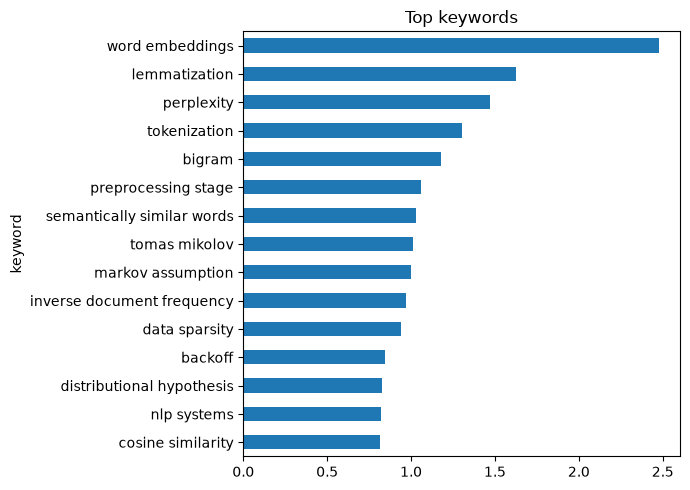

In [5]:
kw_df = pd.DataFrame(keywords[:15], columns=["keyword", "score"]).iloc[::-1]
kw_df.plot.barh(x="keyword", y="score", legend=False, figsize=(7, 5), title="Top keywords")
plt.tight_layout()

## 3. Sentence ranking

A sentence is worth revising if it is information-dense and mentions key concepts:

$$\text{score}(s) = \overline{\text{tfidf}}(s) + 0.5 \sum_{k \in K(s)} \frac{w_k}{\max w}$$

where $K(s)$ is the set of extracted keywords that appear in sentence $s$, and $w_k$ is each keyword's TF-IDF score.

In [6]:
ranked = P.rank_sentences(sentences, keywords, X)
pd.DataFrame([{"score": round(s.score, 3), "page": s.page, "keywords": ", ".join(s.keywords), "sentence": s.text}
              for s in ranked]).head(10)

,score,page,keywords,sentence
0,1.008,2,"word embeddings, semantically similar words, vectors","Word embeddings are dense vector representations of words learned from large corpora, in which semantically similar ..."
1,0.869,2,"word embeddings, tomas mikolov",Word2Vec is a neural model introduced by Tomas Mikolov at Google in 2013 that learns word embeddings by predicting w...
2,0.854,2,"word embeddings, vectors",TF-IDF and word embeddings are two different ways of representing text as vectors.
3,0.826,2,"word embeddings, distributional hypothesis","The distributional hypothesis states that words occurring in similar contexts tend to have similar meanings, and it ..."
4,0.807,2,"lemmatization, tokenization","Tokenization, stop word removal and lemmatization prepare text for analysis."
5,0.631,1,"perplexity, probability",A lower perplexity indicates that the model assigns higher probability to the test data and is therefore a better mo...
6,0.592,1,"tokenization, subwords","Tokenization is the process of splitting raw text into smaller units called tokens, such as words or subwords."
7,0.590,1,"bigram, trigram","An n-gram is a contiguous sequence of n items from a given text, such as a bigram of two words or a trigram of three..."
8,0.566,1,"bigram, probability","Under the bigram model, the probability of a word is estimated from the count of the word pair divided by the count ..."
9,0.561,1,"preprocessing stage, nlp systems","Most NLP systems begin with a preprocessing stage that converts raw text into a clean, consistent form."


## 4. Question generation and answer extraction

Two extractive strategies, tried in order for each ranked sentence:

* **Definition template**: regex patterns for *"X is a Y"*, *"X refers to Y"*, *"X is used to Y"* → **Q:** *What is X?* **A:** *Y*.
* **Cloze deletion (fallback)**: blank out the highest-ranked keyword in the sentence that no earlier card has used → **A:** that keyword.

Filters reject cards that would be useless for revision:
* Definition subjects containing pronouns or question words (*"What are why?"*, *"What is this type of…"*), conjunctions, or digits, or that are too generic (low specificity).
* Cloze answers that are common words (*layer*, *bits*). The blanked term must be multi-word, an acronym, or a rare word.
* Cloze cards whose answer **leaks**: another form of it is still in the sentence (*topology* / *topologies*).
* Sentences that only make sense next to the slide (*"the following figure…"*) or are course admin (*syllabus*, *module 1*).

Every answer is a span of the source sentence, so cards are **grounded** in the notes. Each card stores its source sentence and page number.

In [7]:
candidates = P.generate_cards(ranked, n_cards=15)
cand_df = pd.DataFrame([c.to_dict() for c in candidates])
print(cand_df["kind"].value_counts().to_string())
cand_df[["kind", "question", "answer", "page"]]

kind
cloze         14
definition    10


,kind,question,answer,page
0,definition,What are word embeddings?,"Dense vector representations of words learned from large corpora, in which semantically similar words have similar v...",2
1,cloze,Fill in the blank: Word2Vec is a neural model introduced by _____ at Google in 2013 that learns word embeddings by p...,Tomas Mikolov,2
2,cloze,Fill in the blank: TF-IDF and word embeddings are two different ways of representing text as _____.,vectors,2
3,cloze,"Fill in the blank: The _____ states that words occurring in similar contexts tend to have similar meanings, and it i...",distributional hypothesis,2
4,cloze,"Fill in the blank: Tokenization, stop word removal and _____ prepare text for analysis.",lemmatization,2
5,cloze,Fill in the blank: A lower _____ indicates that the model assigns higher probability to the test data and is therefo...,perplexity,1
6,definition,What is tokenization?,"Process of splitting raw text into smaller units called tokens, such as words or subwords.",1
7,definition,What is an n-gram?,"Contiguous sequence of n items from a given text, such as a bigram of two words or a trigram of three words.",1
8,cloze,"Fill in the blank: Under the _____ model, the probability of a word is estimated from the count of the word pair div...",bigram,1
9,cloze,"Fill in the blank: Most NLP systems begin with a _____ that converts raw text into a clean, consistent form.",preprocessing stage,1


## 5. Duplicate detection with semantic similarity

Notes repeat themselves (the *Summary* section restates earlier material), so the candidate deck contains near-duplicate cards.
Two cards count as duplicates if either:
* their source sentences are **semantically similar**: cosine similarity of **sentence-transformers `all-MiniLM-L6-v2`** embeddings ≥ 0.80 (the threshold is chosen in section 7), or
* they test the **same concept**: same keyword, or one keyword is the **acronym** of the other (*RARP* ↔ *Reverse Address Resolution Protocol*, matched by initials).

Cards are kept greedily in rank order, and definition cards are preferred over cloze cards. If the embedding model is unavailable, the pipeline falls back to TF-IDF cosine similarity.

In [8]:
cards, dupes, method = P.remove_duplicates(candidates, threshold=0.80)
print(f"method={method}: {len(candidates)} candidates -> {len(cards)} cards, {len(dupes)} duplicates removed\n")
for d in dupes:
    print(f"sim={d['similarity']}")
    print("  dropped:", d["dropped"].source)
    print("  kept   :", d["kept"].source, "\n")

method=sentence-transformer: 24 candidates -> 22 cards, 2 duplicates removed

sim=0.546
  dropped: Tokenization, stop word removal and lemmatization prepare text for analysis.
  kept   : Lemmatization is a more principled technique that uses vocabulary and morphological analysis to return the dictionary form of a word, called the lemma. 

sim=0.515
  dropped: A lower perplexity indicates that the model assigns higher probability to the test data and is therefore a better model.
  kept   : Perplexity is the standard intrinsic evaluation metric for language models and measures how well a model predicts a held-out test set. 



**Why embeddings rather than TF-IDF here?** TF-IDF cosine similarity only rewards shared words. Embeddings also catch paraphrases.
The cell below compares the two methods on one paraphrased pair and one unrelated pair.

In [9]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer

pairs = [
    ("Smoothing redistributes probability mass so unseen n-grams get non-zero probability.",
     "Techniques that give a small probability to word sequences never observed in training."),
    ("Smoothing redistributes probability mass so unseen n-grams get non-zero probability.",
     "Named entity recognition classifies entities into person, organization and location."),
]
model = P.get_embedder()
rows = []
for a, b in pairs:
    tf = TfidfVectorizer(stop_words="english").fit([a, b])
    t = cosine_similarity(tf.transform([a]), tf.transform([b]))[0, 0]
    e = cosine_similarity(model.encode([a]), model.encode([b]))[0, 0] if model else float("nan")
    rows.append({"pair": "paraphrase" if rows == [] else "unrelated", "tfidf_cosine": round(t, 3), "embedding_cosine": round(float(e), 3)})
pd.DataFrame(rows)

,pair,tfidf_cosine,embedding_cosine
0,paraphrase,0.132,0.419
1,unrelated,0.000,0.037


## 6. Coverage: which concepts are missing from the deck?

A keyword counts as **covered** if it appears in any card's question or answer. Missing concepts are shown in the app so the student knows what to add.

In [10]:
cards = cards[:15]
cov = P.coverage(cards, keywords)
print(f"Coverage: {cov['ratio']:.0%}")
print("Missing:", cov["missing"])

Coverage: 80%
Missing: ['inverse document frequency', 'backoff', 'multiset', 'crude heuristic', 'vocabulary morphological analysis']


## 7. Evaluation

| Metric | What it checks |
|---|---|
| **Grounding rate** | % of answers that literally occur in the source sentence and in the document |
| **Keyword coverage vs deck size** | How quickly the deck covers the top concepts as it grows |
| **Redundancy** | Mean nearest-neighbour similarity between cards, before and after deduplication |
| **Human rating** | Manual 1–3 rating of question quality (export below) |

In [11]:
full_text = " ".join(s.text for s in sentences).lower()   # same cleaning the pipeline used
grounded_src = sum(c.answer.rstrip(".").lower() in c.source.lower() for c in cards)
grounded_doc = sum(c.answer.rstrip(".").lower() in full_text for c in cards)
print(f"Answer found in its source sentence: {grounded_src}/{len(cards)}")
print(f"Answer found in the document       : {grounded_doc}/{len(cards)}")

Answer found in its source sentence: 15/15
Answer found in the document       : 15/15


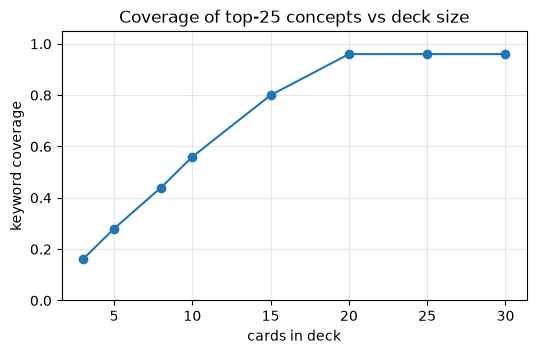

In [12]:
sizes = [3, 5, 8, 10, 15, 20, 25, 30]
ratios = []
for n in sizes:
    c, _, _ = P.remove_duplicates(P.generate_cards(ranked, n_cards=n))
    ratios.append(P.coverage(c[:n], keywords)["ratio"])
plt.figure(figsize=(6, 3.5))
plt.plot(sizes, ratios, marker="o")
plt.xlabel("cards in deck"); plt.ylabel("keyword coverage"); plt.ylim(0, 1.05)
plt.title("Coverage of top-25 concepts vs deck size"); plt.grid(alpha=.3)

In [13]:
import os
import numpy as np

def redundancy(card_list):
    E, _ = P.embed([c.source for c in card_list])
    S = cosine_similarity(E); np.fill_diagonal(S, 0)
    return S.max(axis=1).mean()

print(f"Mean nearest-neighbour similarity  before dedup: {redundancy(candidates):.3f}  ({len(candidates)} cards)")
print(f"                                   after  dedup: {redundancy(cards):.3f}  ({len(cards)} cards)")

Mean nearest-neighbour similarity  before dedup: 0.555  (24 cards)
                                   after  dedup: 0.532  (15 cards)


### 7.1 Choosing the duplicate threshold: TF-IDF vs embeddings

`evaluation/dup_pairs.csv` holds 20 hand-labelled sentence pairs, mostly from the Computer Networks lectures: 9 duplicates and 11 non-duplicates.
Several non-duplicates are deliberately hard: they share most of their words or topic but mean different things (*subnetting vs supernetting*, *IPv4 vs IPv6*, *ARP vs RARP*).

,method,threshold,precision,recall,F1
23,embedding,0.8,1.00,0.67,0.80
0,tfidf,0.3,0.56,0.56,0.56


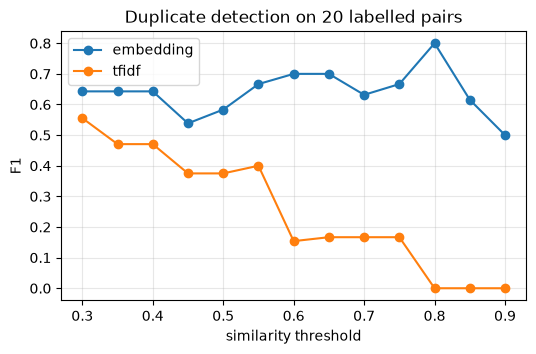

In [14]:
pairs = pd.read_csv("evaluation/dup_pairs.csv")
tf = TfidfVectorizer(stop_words="english").fit(list(pairs.a) + list(pairs.b))
pairs["tfidf"] = [cosine_similarity(tf.transform([a]), tf.transform([b]))[0, 0] for a, b in zip(pairs.a, pairs.b)]
pairs["embedding"] = [float(cosine_similarity(model.encode([a]), model.encode([b]))[0, 0]) for a, b in zip(pairs.a, pairs.b)]

def prf(scores, labels, t):
    pred = scores >= t
    tp, fp, fn = (pred & labels).sum(), (pred & ~labels).sum(), (~pred & labels).sum()
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn)
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)

labels = pairs.duplicate.astype(bool)
thresholds = np.round(np.arange(0.3, 0.95, 0.05), 2)
res = pd.DataFrame([{"method": m, "threshold": t, **dict(zip(["precision", "recall", "F1"], prf(pairs[m], labels, t)))}
                    for m in ["tfidf", "embedding"] for t in thresholds])
fig, ax = plt.subplots(figsize=(6, 3.5))
for m, g in res.groupby("method"):
    ax.plot(g.threshold, g.F1, marker="o", label=m)
ax.set_xlabel("similarity threshold"); ax.set_ylabel("F1"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Duplicate detection on 20 labelled pairs")
res.loc[res.groupby("method").F1.idxmax()].round(2)

In [15]:
# hardest cases: non-duplicates that look alike
pairs[~labels].sort_values("embedding", ascending=False).head(4)[["a", "b", "tfidf", "embedding"]].round(2)

,a,b,tfidf,embedding
19,Class C addresses have their first three bits set to 110.,Class B addresses have their first two bits set to 10.,0.76,0.79
14,IPv4 has a 32-bit address length.,IPv6 has a 128-bit address length.,0.53,0.79
11,Subnetting divides a network into smaller networks.,Supernetting combines several small networks into one larger network.,0.27,0.77
12,ARP finds the MAC address of a device from its IP address.,RARP finds the IP address of a device from its MAC address.,0.86,0.70


Embeddings beat TF-IDF clearly. Their failure mode is pairs that are near opposites (*IPv4 / IPv6*), which a bag-of-meaning model scores as similar.
0.80 is the best threshold on this set, so it is the pipeline default.
Caveat: the threshold was tuned on the same 20 pairs it is evaluated on, so a held-out set would give a fairer estimate.

### 7.2 Testing on real lecture slides

The sample notes are clean prose. Real lecture PDFs are slide decks: bullet fragments, headings, glued-together words, figures, and syllabus pages.
Running the pipeline on two Computer Networks modules drove most of the preprocessing rules in section 1 (slide-aware line joining, merged-word repair, figure/syllabus filtering, the leak check for cloze cards).

In [16]:
DOCS = {"NLP sample notes": "sample_notes.pdf",
        "CN Module 1": os.path.expanduser("~/Downloads/Module_1_CN.pdf"),
        "CN Module 3.1": os.path.expanduser("~/Downloads/Mod_3.1_CN.pdf")}
summary = []
for name, path in DOCS.items():
    if not os.path.exists(path):
        continue
    d = P.build_deck(path, n_cards=20)
    full = " ".join(P.clean_text(t) for _, t in P.extract_pages(path)).lower()
    summary.append({"document": name, **{k: d["stats"][k] for k in ["pages", "sentences", "cards"]},
                    "duplicates_removed": len(d["duplicates"]), "coverage": d["coverage"]["ratio"],
                    "grounded": sum(c.answer.rstrip(".").lower() in c.source.lower() for c in d["cards"]) / len(d["cards"])})
pd.DataFrame(summary)

,document,pages,sentences,cards,duplicates_removed,coverage,grounded
0,NLP sample notes,2,34,20,2,0.96,1.0
1,CN Module 1,78,210,20,1,0.68,1.0
2,CN Module 3.1,118,468,20,8,0.84,1.0


### 7.3 Question quality ratings

Each card is rated 3 = good, 2 = usable, 1 = bad.
`evaluation/ratings_claude.csv` holds ratings of the 60 cards above **made by Claude (an AI), not a human**. Use them as a preliminary check only.
For the report, rate the cards yourself in `evaluation/ratings_human.csv` (the next cell creates it). Ideally ask a classmate too, and compare the two raters.

In [17]:
ai = pd.read_csv("evaluation/ratings_claude.csv")
print("AI ratings, by document:")
print(ai.groupby("document").rating.agg(["mean", "count"]).round(2), "\n")
print("AI ratings, by card type:")
print(ai.groupby("kind").rating.agg(["mean", "count"]).round(2))
ai[ai.rating == 1][["document", "question", "note"]]

AI ratings, by document:
                  mean  count
document                     
CN Module 1       2.30     20
CN Module 3.1     2.50     20
NLP sample notes  2.95     20 

AI ratings, by card type:
            mean  count
kind                   
cloze       2.36     39
definition  3.00     21


,document,question,note
4,CN Module 1,"Fill in the blank: Defines specific protocols: TCP, _____, IP, HTTP, etc. Used as reference for teaching/network des...",guess one item from a list
7,CN Module 1,"Fill in the blank: Components of a computer network: Classification of networks, Network _____, networking devices (...",syllabus line
8,CN Module 1,Fill in the blank: Each _____ has its own strengths and weaknesses.,too vague to answer
14,CN Module 1,Fill in the blank: Code _____ : Also known as code division multiple access.,answer leaks via 'code division multiple access'
15,CN Module 1,Fill in the blank: Department of Defense-DoD worry about _____ going down.,out of context
37,CN Module 3.1,Fill in the blank: The Graphs can be categorized into two types: _____.,"answer incomplete (two types, only one given)"
39,CN Module 3.1,"Fill in the blank: Thats why if a _____ is used, the data flow would be 8 Mbps for 9 seconds.",depends on previous slide


In [18]:
HUMAN = "evaluation/ratings_human.csv"
if not os.path.exists(HUMAN):
    ai.drop(columns=["rating", "rater", "note"]).assign(rating="").to_csv(HUMAN, index=False)
    print(f"Wrote {HUMAN}. Fill in the rating column and re-run this cell.")
else:
    h = pd.read_csv(HUMAN).dropna(subset=["rating"])
    if len(h):
        print(h.groupby("kind").rating.agg(["mean", "count"]).round(2))
        both = h.merge(ai, on=["document", "id"], suffixes=("_human", "_ai"))
        print("\nexact agreement with AI ratings:", round((both.rating_human == both.rating_ai).mean(), 2))

Wrote evaluation/ratings_human.csv. Fill in the rating column and re-run this cell.


## 8. Full pipeline (what the app calls)

`app.py` only calls `build_deck`. Run the app with:

```bash
.venv/bin/streamlit run app.py
```

In [19]:
deck = P.build_deck(SOURCE, n_cards=15)
deck["stats"], deck["coverage"]["ratio"]

({'pages': 2,
  'sentences': 34,
  'candidates': 24,
  'cards': 15,
  'similarity_method': 'sentence-transformer'},
 0.8)